# Examining Sub-Research Research Question 3: Word Count

The third sub-research question is as follows: **'Are there differences in content between homosexual and heterosexual fan fiction on Archive of Our Own, regarding variables such as the language, date published, or word count?**

In [1]:
# Import package
import polars as pl
import pyarrow
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_metadata = pl.read_ndjson("./data/combined_metadata.jsonl") # Create the df_metadata DataFrame
df_metadata = df_metadata.unnest('metadata') # Turn the metadata column into 18 separate columns

fandoms = ["DC's Legends of Tomorrow (TV)", "Avatar: The Last Airbender (Cartoon 2005)", "Spider-Man: Spider-Verse (Sony Animated Movies)"]

# Select the target fandom and relationship categories
df_metadata = df_metadata.filter(
    ((pl.col("Fandom") == fandoms[0]) |
    (pl.col("Fandom") == fandoms[1]) |
    (pl.col("Fandom") == fandoms[2])) &
    ((pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M") |
    (pl.col("Category") == "F/M"))
)

df_metadata.head()

id,title,Additional Tags,Archive Warning,Category,Characters,Fandoms,Language,Rating,Relationship,author,chapters,completed,published,words,Fandom,Character,Collections,Series,Relationships
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""10012010""","""Just One Training""","""Explicit Sexual Content, Oral …","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""Explicit""","""Sara Lance/Leonard Snart""","""by capnwho""","""1/1""","""""","""2017-02-28""","""1,470""","""DC's Legends of Tomorrow (TV)""",null,null,"""Just One Fixation""",null
"""10013705""","""Five Months More""","""Established Relationship, surp…","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart""",null,"""English""","""Not Rated""",null,"""by flabbergabst""","""1/1""","""""","""2017-02-28""","""505""","""DC's Legends of Tomorrow (TV)""",null,null,"""The Captain Canary Collection""","""Sara Lance/Leonard Snart, Capt…"
"""10018964""","""It Ends with a Kiss""","""Alpha/Beta/Omega Dynamics, Min…","""No Archive Warnings Apply""","""M/M""","""Leonard Snart, Ray Palmer, Mic…",null,"""English""","""Teen And Up Audiences""","""Ray Palmer/Leonard Snart""","""by Constantsnow""","""1/1""","""""","""2017-02-28""","""3,008""","""DC's Legends of Tomorrow (TV)""",null,null,null,null
"""10030784""","""Bet""",null,"""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""General Audiences""","""Sara Lance/Leonard Snart""","""by orphan_account""","""1/1""","""""","""2017-03-01""","""1,273""","""DC's Legends of Tomorrow (TV)""",null,null,null,null
"""10033958""","""For the Both of Us""","""Captain Canary, ficcingcaptain…","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""Not Rated""",null,"""by flabbergabst""","""1/1""","""""","""2017-03-01""","""1,067""","""DC's Legends of Tomorrow (TV)""",null,null,"""The Captain Canary Collection""","""Sara Lance/Leonard Snart, Capt…"


In [3]:
df_metadata = df_metadata.with_columns(pl.col("words").str.replace_all(",", "").cast(pl.Int64, strict=False)) # change str to int

In [ ]:
# Calculate the word_count frequencies
ff_mm_word_count_amt = df_metadata.filter(
    (pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")
).select(pl.col("words").value_counts()).unnest("words").sort("count", descending=True) # Filtered by F/F + M/M
fm_word_count_amt = df_metadata.filter(
    (pl.col("Category") == "F/M")
).select(pl.col("words").value_counts()).unnest("words").sort("count", descending=True) # Filtered by F/M

In [5]:
# Create lists
ff_mm_word_count_list = ff_mm_word_count_amt.to_series().to_list()
fm_word_count_list = fm_word_count_amt.to_series().to_list()

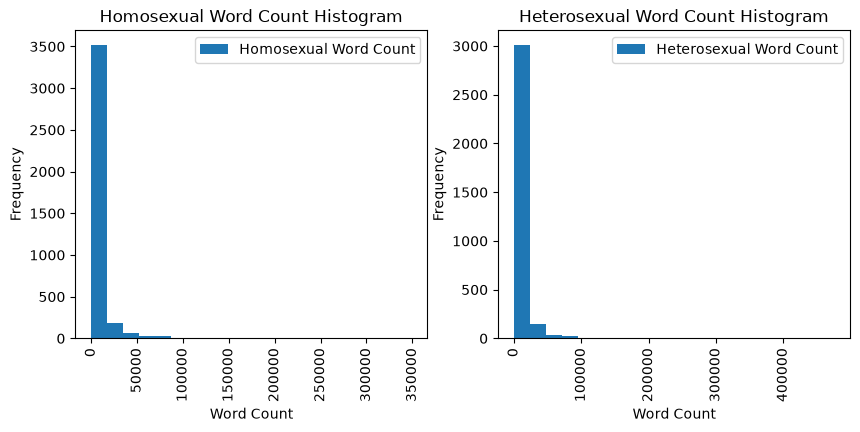

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# Filtered by F/F + M/M
ax[0].hist(ff_mm_word_count_amt['words'], bins=20)

ax[0].set_title("Homosexual Word Count Histogram")
ax[0].set_xlabel("Word Count")
ax[0].set_ylabel("Frequency")
ax[0].tick_params(axis="x", labelrotation=90)

ax[0].legend(['Homosexual Word Count'])

# Filtered by F/M
ax[1].hist(fm_word_count_amt['words'], bins=20)

ax[1].set_title("Heterosexual Word Count Histogram")
ax[1].set_xlabel("Word Count")
ax[1].set_ylabel("Frequency")
ax[1].tick_params(axis="x", labelrotation=90)

ax[1].legend(['Heterosexual Word Count'])
plt.show()

## 1. Ratings

### 1.1 Creating the Ratings Datasets

In [7]:
ratings = ["Not Rated", "General Audiences", "Teen And Up Audiences", "Mature", "Explicit"]

ff_mm_wc_ratings = pl.DataFrame()
for rating in ratings:
    ff_mm_wc_rating = df_metadata.filter(
        ((pl.col("Category") == "F/F") |
        (pl.col("Category") == "M/M")) &
        (pl.col("Rating") == rating)
    ).select(pl.col("words").value_counts()).unnest("words").with_columns(new_column = pl.lit(rating)).rename({"new_column": "Rating"})
    ff_mm_wc_ratings = pl.concat([ff_mm_wc_ratings, ff_mm_wc_rating])

ff_mm_wc_ratings

words,count,Rating
i64,u32,str
1456,1,"""Not Rated"""
24032,1,"""Not Rated"""
6446,1,"""Not Rated"""
75162,1,"""Not Rated"""
3607,1,"""Not Rated"""
…,…,…
11305,1,"""Explicit"""
20726,1,"""Explicit"""
2305,1,"""Explicit"""


### 1.2 Visualizing the Ratings Datasets

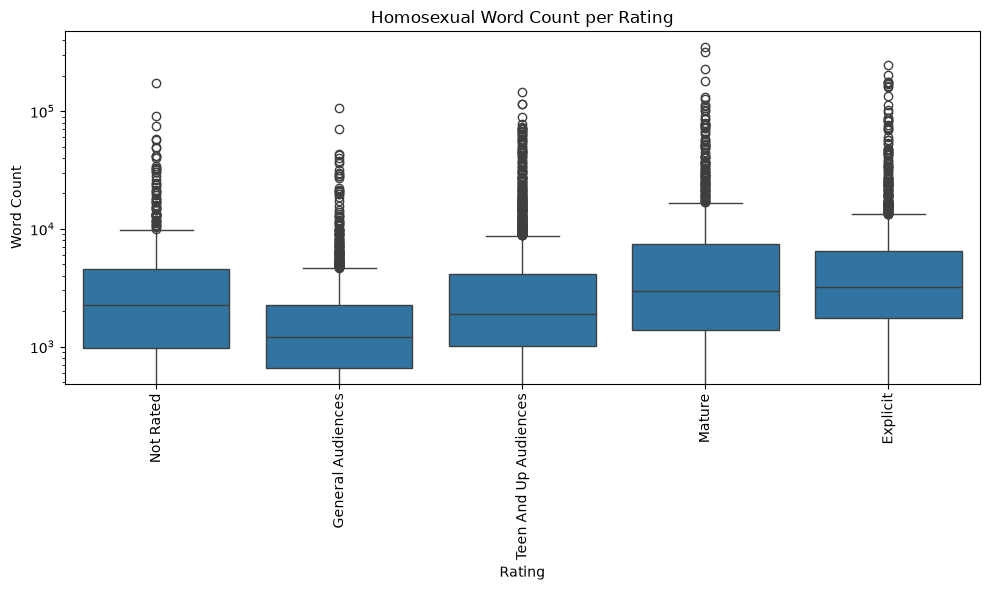

In [ ]:
# Filtered by F/F + M/M
ff_mm_ratings_boxplot = ff_mm_wc_ratings.to_pandas() # Convert Polars to pandas
ff_mm_ratings_boxplot = ff_mm_ratings_boxplot.loc[ff_mm_ratings_boxplot.index.repeat(ff_mm_ratings_boxplot["count"])] # Repeat each row according to its frequency

# Create the box plots
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=ff_mm_ratings_boxplot,
    x="Rating",
    y="words"
)

plt.yscale("log")

plt.xlabel("Rating")
plt.ylabel("Word Count")
plt.title("Homosexual Word Count per Rating")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()